# RQ2: does compression keep the predictive signal?

A fuller, synthetic-data walkthrough of the code behind `scripts/run_experiment.py` (single
nested-CV comparison of raw against each embedding) and `scripts/run_repeated_cv.py` (the same
comparison repeated over several outer-fold seeds, paired so a raw-vs-embedding difference can
be given an interval). Both call the same function, `metabo.evaluation.evaluate` /
`nested_cv_oof`, which is what actually runs here, inline.

Embedding dimensions are reduced to `{2, 16}` (the study uses `{2, 3, 4, 8, 16}`) and the
bootstrap count to 100 (the study uses 1000), purely for speed; nothing about the method
differs. See the top-level `README.md` for the real settings. The data in `data/` is
purely synthetic, drawn from chosen statistical distributions, not derived from any real
data (see `00_build_data.ipynb`).


In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

REPO_ROOT = Path.cwd().parent
SRC_DIR = REPO_ROOT / "src"
DATA_DIR = REPO_ROOT / "data"
sys.path.insert(0, str(SRC_DIR))
sys.path.insert(0, str(SRC_DIR / "analysis"))
# So a subprocess started from here (python "scripts/some_script.py") can "from metabo
# import ..." too, exactly as if the package had been pip installed.
os.environ["PYTHONPATH"] = str(SRC_DIR)
os.environ["METABO_DATA_DIR"] = str(DATA_DIR)
os.environ["METABO_RESULTS_DIR"] = str(Path.cwd() / "results")

# data/ is not shipped with the repo -- generate it on first use, same recipe as
# 00_build_data.ipynb, if it is not already there.
_RENAMED = {
    "datacorr_6m6y18mMw1w24_final.csv": "synthetic_raw_metabolome.csv",
    "target_for_metabolites_ml.csv": "synthetic_targets.csv",
    "metabolites_6m_for_ml.csv": "synthetic_metabolites_6m.csv",
    "metabolites_18m_for_ml.csv": "synthetic_metabolites_18m.csv",
    "metabolites_6y_for_ml.csv": "synthetic_metabolites_6y.csv",
}
if not all((DATA_DIR / new).exists() for new in _RENAMED.values()):
    import subprocess
    import shutil
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.run([sys.executable, str(SRC_DIR / "scripts" / "make_synthetic_data.py"),
                    "--outdir", str(DATA_DIR), "--force"], check=True, capture_output=True)
    subprocess.run([sys.executable, str(SRC_DIR / "scripts" / "build_inputs.py"),
                    "--source", str(DATA_DIR / "datacorr_6m6y18mMw1w24_final.csv"),
                    "--outdir", str(DATA_DIR)], check=True, capture_output=True)
    for old, new in _RENAMED.items():
        shutil.move(str(DATA_DIR / old), str(DATA_DIR / new))
    print("generated data/ (not shipped with the repo)")
# The synthetic data files are named distinctly from metabo.config's own default filenames,
# so every script that reads them -- in this process or in a subprocess started from here --
# is told explicitly which files to use.
os.environ["METABO_SOURCE"] = str(DATA_DIR / "synthetic_raw_metabolome.csv")
os.environ["METABO_TARGET_FILE"] = str(DATA_DIR / "synthetic_targets.csv")
os.environ["METABO_METAB_6M"] = str(DATA_DIR / "synthetic_metabolites_6m.csv")
os.environ["METABO_METAB_18M"] = str(DATA_DIR / "synthetic_metabolites_18m.csv")
os.environ["METABO_METAB_6Y"] = str(DATA_DIR / "synthetic_metabolites_6y.csv")
# The synthetic metabolites are named generically (metabolite001, ...), not with real
# chemical nomenclature, so the attribution scripts are told which generic name is the
# planted fish-oil marker (and its weaker parent compound).
os.environ["METABO_FISHOIL_MARKER"] = "metabolite001"
os.environ["METABO_FISHOIL_MARKER_PARENT"] = "metabolite002"
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("NUMBA_THREADING_LAYER", "workqueue")

# Reduced from the study's settings (1000 bootstraps/permutations, all five embedding
# dimensions, ten repeats) so every cell below finishes in well under a minute.
os.environ["METABO_N_BOOTSTRAP"] = "100"
os.environ["METABO_N_PERMUTATION"] = "200"
os.environ["METABO_EMBED_DIMS"] = "2 16"
os.environ["METABO_VAE_MAX_EPOCHS"] = "40"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from metabo import config, data_io, evaluation

print("embedding dims used here:", config.EMBED_DIMS, "(study default: 2 3 4 8 16)")


embedding dims used here: [2, 16] (study default: 2 3 4 8 16)


## 1. Single-split nested-CV comparison

What `scripts/run_experiment.py` writes: one record per timepoint, outcome, representation,
dimension and classifier. Here for `sex` (planted signal, positive control) and `vitd` (no
planted signal, negative control) at 6 months, logistic regression, raw vs PCA vs UMAP (vs the
VAE if PyTorch is installed).


In [2]:
X_6m = data_io.load_metabolites("6m")
targets = data_io.load_targets()

reps = ["raw", "pca", "umap"]
try:
    import torch  # noqa: F401
    reps.append("vae")
except ImportError:
    print("torch not installed -- skipping vae (pip install torch to enable)")

rows = []
for outcome in ["sex", "vitd"]:
    X, y = data_io.align(X_6m, targets[outcome])
    for rep in reps:
        dims = [None] if rep == "raw" else config.EMBED_DIMS
        for dim in dims:
            rec, _ = evaluation.evaluate(X, y, rep, dim or 2, "lr", random_state=config.SEED)
            rows.append({"outcome": outcome, "representation": rep, "dim": dim or "-",
                         "auroc": round(rec["auroc"], 3),
                         "auroc_ci": f"{rec['auroc_lo']:.2f} to {rec['auroc_hi']:.2f}"})

single_split = pd.DataFrame(rows)
single_split


,outcome,representation,dim,auroc,auroc_ci
0,sex,raw,-,0.751,0.69 to 0.81
1,sex,pca,2,0.483,0.42 to 0.56
2,sex,pca,16,0.529,0.46 to 0.60
3,sex,umap,2,0.472,0.39 to 0.53
4,sex,umap,16,0.497,0.42 to 0.58
5,sex,vae,2,0.571,0.51 to 0.65
6,sex,vae,16,0.410,0.35 to 0.48
7,vitd,raw,-,0.458,0.39 to 0.53
8,vitd,pca,2,0.498,0.43 to 0.57
9,vitd,pca,16,0.548,0.48 to 0.63


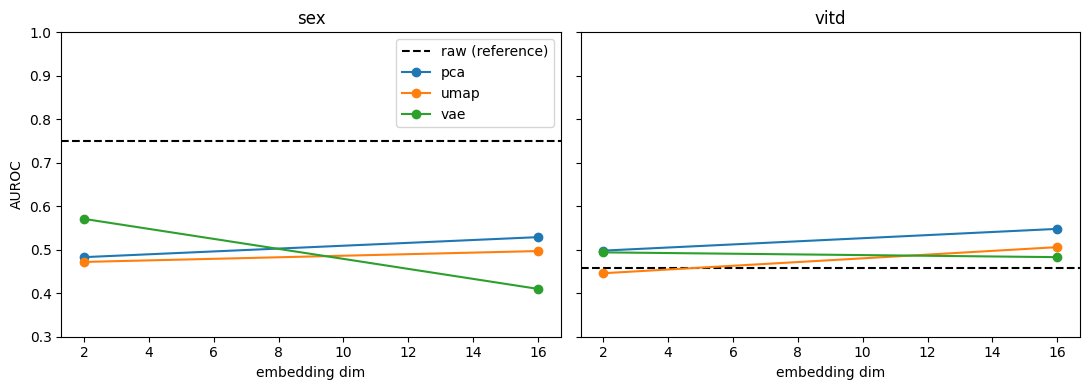

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, outcome in zip(axes, ["sex", "vitd"]):
    sub = single_split[single_split.outcome == outcome]
    raw_auc = sub.loc[sub.representation == "raw", "auroc"].iloc[0]
    ax.axhline(raw_auc, color="black", linestyle="--", label="raw (reference)")
    for rep in ["pca", "umap", "vae"]:
        s = sub[sub.representation == rep]
        if len(s):
            ax.plot(s["dim"], s["auroc"], marker="o", label=rep)
    ax.set_title(outcome); ax.set_xlabel("embedding dim"); ax.set_ylim(0.3, 1.0)
axes[0].set_ylabel("AUROC"); axes[0].legend()
fig.tight_layout()


`sex` should show every embedding sitting well below the raw reference line (the
headline finding, reproduced on synthetic data); `vitd` has no planted signal, so raw and every
embedding should sit near chance regardless.

## 2. Repeated cross-validation, paired difference with an interval

What `scripts/run_repeated_cv.py` writes, and `analysis/summarize_repeated_cv.py` summarizes:
the classifier is fixed (logistic regression, no selection on the outer folds), repeated over
several seeds, with raw and the embedding sharing the same outer folds within a repeat so the
per-fold difference is paired. Reduced here to 3 repeats and one embedding/dimension (the study
uses 10 repeats and reports every embedding and dimension); the interval construction (mean
difference, Nadeau-Bengio corrected variance, t-interval) is exactly
`analysis/summarize_repeated_cv.py`'s own `nb()`/`row()` functions, reproduced inline.


In [4]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from scipy import stats

OUTCOME, REP, DIM, N_REPEATS = "sex", "pca", 16, 3
X, y = data_io.align(X_6m, targets[OUTCOME])
Xv, yv = X.values, y.values

diffs = []
for repeat in range(N_REPEATS):
    seed = config.SEED + repeat
    _, oof_raw = evaluation.nested_cv_oof(X, y, "raw", 2, "lr", random_state=seed)
    _, oof_emb = evaluation.nested_cv_oof(X, y, REP, DIM, "lr", random_state=seed)
    outer = StratifiedKFold(config.OUTER_K, shuffle=True, random_state=seed)
    for _, te in outer.split(Xv, yv):
        diffs.append(roc_auc_score(yv[te], oof_raw[te]) - roc_auc_score(yv[te], oof_emb[te]))

diffs = np.array(diffs)
n_folds = N_REPEATS * config.OUTER_K
mean = diffs.mean()
se = np.sqrt((1 / n_folds + 1 / (config.OUTER_K - 1)) * diffs.var(ddof=1))
t = stats.t.ppf(0.975, n_folds - 1)
print(f"{OUTCOME}, raw minus {REP} (k={DIM}), {N_REPEATS} repeats x {config.OUTER_K} folds:")
print(f"  mean difference {mean:.3f}, 95% CI {mean - t*se:.3f} to {mean + t*se:.3f}")


sex, raw minus pca (k=16), 3 repeats x 5 folds:
  mean difference 0.223, 95% CI 0.143 to 0.303


## Next steps

- Run the full grid as batch jobs instead of inline (results written to `results/`,
  resume-safe if run again):

```bash
cd ../src
export METABO_DATA_DIR=../data METABO_RESULTS_DIR=../notebooks/results
python scripts/run_experiment.py --timepoints 6m --targets sex vitd fishoil --reps raw pca umap
python scripts/run_repeated_cv.py --reps raw pca umap --repeats 0 1 2 --run-tag nb
```

- `analysis/summarize_repeated_cv.py` does this same paired-difference calculation for every
  outcome, pools positive controls vs "all pairs", and adds a Wilcoxon test across outcomes --
  worth reading once this notebook's single-pair version makes sense.
